# **Predicción de demanda de pasajeros para la optimización de frecuencias de transporte — SOBUSA v1.0**

**Data Challenge SOBUSA · Ciencia de Datos | Versión `sobusa-v1.0-p25-d3-r01` | 22 de noviembre de 2026**

## **Resumen**

Estimamos el conteo de pasajeros asociado a salidas programadas de las rutas 2, 16 y 21 mediante ventanas móviles de 30, 60 y 120 minutos. El sistema combina cinco modelos RRAP v4 y cinco LightGBM L3, promediados por familia y ponderados 50/50. En la evaluación retrospectiva p25 con historia D−3, el MASE del ensamble fue **0,580325**, frente a **0,587081** de RRAP y **0,593973** de LightGBM. La disponibilidad efectiva de la información antes de la emisión sigue por acreditar para operación en fechas nuevas.

**Objetivos.** Documentar el conjunto y sus reglas de disponibilidad, justificar el diseño de la evaluación, reproducir las métricas desde el archivo verificado cuando se suministre y ejecutar la inferencia con los pesos congelados.

**Alcance.** La edición pública incluye metodología, resultados globales autorizados y código ejecutable. Las celdas con acceso a históricos, pronósticos por ventana y activos se habilitan localmente. Sus salidas detalladas permanecen privadas.

### **Contenido**

1. Introducción
2. Fundamentación teórica y estado del arte
3. Datos y análisis exploratorio
4. Preparación de datos
5. Diseño experimental
6. Modelo RRAP v4
7. Modelo LightGBM L3
8. Ensamble SOBUSA v1.0
9. Métricas de evaluación
10. Resultados experimentales
11. Inferencia reproducible
12. Integración con SOBUSA
13. Discusión y limitaciones
14. Conclusiones
15. Reproducibilidad y referencias

## **1. Introducción**

### **1.1. Problema de investigación**

Planificar frecuencias exige anticipar en qué momentos el servicio puede afrontar mayor presión de pasajeros. Una media diaria oculta picos de corta duración y no permite distinguir una necesidad de despacho a 30 minutos de una decisión sobre una o dos horas. En las rutas 2, 16 y 21, el problema consiste en producir pronósticos comparables para esas tres duraciones con la información que podría estar disponible al inicio del día. Los conteos representan pasajeros asociados a viajes elegibles, asignados a su salida programada. La interpretación está condicionada al servicio observado y a la calidad de su medición.

La pregunta evaluada es si un promedio fijo de dos familias mejora el error agregado de cada una en ventanas emparejadas del cierre retrospectivo. Una pregunta distinta, todavía abierta, es si ese beneficio se sostiene en fechas futuras con un registro operativo de entradas y recepciones. La distinción evita interpretar la disponibilidad en una extracción final como prueba de disponibilidad el día de emisión.

### **1.2. Enfoque de investigación y contribuciones**

El estudio fija primero la unidad de observación, el contrato D−3 y la rejilla, conserva un conjunto evaluable común y separa ajuste, selección y evaluación cronológicamente. RRAP v4 usa una representación convolucional y un ancla histórica para producir una curva intradía. LightGBM L3 pronostica directamente sobre cada ventana. En cada familia se promedian cinco semillas y después se promedian las dos familias a partes iguales. La ponderación fija permite evaluar una regla transparente sin elegir el peso en p25.

La contribución empírica es una comparación emparejada por ruta, tiempo y horizonte, acompañada de análisis de estabilidad, complementariedad y errores segmentados. La contribución de ingeniería es un motor de inferencia común para Python, Jupyter y FastAPI, con comprobación de integridad de los modelos. La simulación de frecuencias utiliza el pronóstico a 60 minutos como entrada de un cálculo separado. El capítulo de resultados compara errores de conteo, sin atribuirle efectos medidos sobre tiempos de espera, flota o calidad de servicio.

### **1.3. Organización del notebook**

El capítulo 2 fundamenta el diseño con la literatura. Los capítulos 3–5 describen datos, disponibilidad y evaluación cronológica. Los capítulos 6–9 desarrollan los modelos, la combinación y las métricas. El capítulo 10 interpreta los resultados del cierre. Los capítulos 11 y 12 ejecutan y explican la inferencia común. Los capítulos finales delimitan la evidencia y enlazan cada bloque con sus fuentes originales.

## **2. Fundamentación teórica y estado del arte**

### **2.1. La demanda como señal para la planificación del servicio**

En transporte público, los conteos observados reflejan tanto la demanda atendida como las condiciones del servicio prestado. Los perfiles intradía responden a patrones de actividad y a diferencias de calendario, mientras que la oferta, las cancelaciones y la calidad de registro modifican lo que puede medirse. SOBUSA pronostica **pasajeros asociados a viajes programados elegibles**. La utilidad operativa de ese conteo depende del horizonte de decisión, de la capacidad por vehículo y de la disponibilidad de flota. El resultado de error estadístico no mide por sí solo tiempos de espera, congestión ni beneficios de una política de despacho.

**Rocco di Torrepadula et al. (2024).** Sistematizaron estudios de aprendizaje automático sobre demanda de transporte público, incluyendo fuentes, sensores y variables externas. Identificaron una escasez de conjuntos abiertos y estudios reproducibles, junto con una atención desigual a costos e interpretabilidad. La revisión local de demanda fundamenta **explicitar qué mide el conteo y separar la reproducción pública de la evaluación con datos autorizados**. No valida la definición local de elegibilidad, la cobertura de las tres rutas ni los efectos de usar el modelo para decidir frecuencias.

### **2.2. Aprendizaje profundo y representación temporal**

**Smyl (2020).** Estudió el pronóstico de numerosas series en la competencia M4 mediante un modelo híbrido de suavización exponencial y redes recurrentes. La combinación permitió representar nivel y estacionalidad mediante componentes estructurados y aprovechar el aprendizaje entre series con una red, con buen desempeño en ese banco de pruebas. En SOBUSA fundamenta **separar un perfil de referencia de una corrección aprendida**. RRAP usa convoluciones y un ancla de perfiles y rezagos; el estudio de Smyl no verifica esa arquitectura ni su desempeño en transporte.

**Challu et al. (2023).** Propusieron N-HiTS para pronósticos de horizonte largo, combinando muestreo a varias tasas e interpolación jerárquica. Los experimentos mostraron ventajas de precisión y costo computacional en los bancos evaluados. En SOBUSA fundamenta **representar patrones a distintas resoluciones**. Las ramas dilatadas y de 1–2 horas del decodificador RRAP son una adaptación del principio multiescala. El artículo no valida las capas concretas de RRAP ni acredita mejoras en nuestras ventanas móviles.

Una convolución temporal comparte filtros entre posiciones de la serie. Las primeras capas pueden representar cambios locales, mientras el apilamiento, la dilatación y el agrupamiento permiten integrar un contexto más amplio. En RRAP, la máscara informa qué valores estaban disponibles. El calendario y la representación de franja distinguen patrones que pueden ocupar posiciones distintas según el día.

### **2.3. Boosting y ajuste de conteos**

**Ke et al. (2017).** Presentaron LightGBM para reducir el costo del ajuste de árboles por boosting. El trabajo estudió GOSS y EFB y contrastó tiempo y precisión con otros métodos en datos públicos. Fundamenta **usar un segundo estimador basado en árboles** capaz de capturar umbrales e interacciones entre variables de ventana. La receta L3 usa las opciones archivadas y fracciones de muestreo de 1,0. Los resultados de eficiencia del artículo no establecen que GOSS se haya activado ni validan la configuración Poisson o L3 de SOBUSA.

**Gneiting (2011).** Estudió la evaluación de pronósticos puntuales desde teoría de decisiones y caracterizó pérdidas coherentes con el funcional que se quiere predecir. En particular, la pérdida absoluta favorece la mediana y las pérdidas de Bregman pueden ser coherentes con la media. En SOBUSA fundamenta **distinguir objetivo de ajuste y criterio de evaluación**. Para una intensidad positiva, la pérdida Poisson sin constantes es $L(y,\mu)=\mu-y\log\mu$ y su mínimo esperado condicional corresponde a la media. Evaluamos con MASE y damos la misma ponderación a las ventanas después de escalar sus errores. Este marco no demuestra equidispersión, independencia de ventanas ni calibración probabilística.

### **2.4. Ensambles, diversidad y reconciliación**

**Montero-Manso et al. (2020).** En FFORMA, los autores aprendieron pesos a partir de características de series y contrastaron el promedio dependiente de la serie en M4. El estudio muestra que puede ser útil aprender cuándo confiar más en un pronóstico. Fundamenta **considerar una combinación aprendida como comparación de desarrollo**. La versión congelada usa pesos iguales. FFORMA no demuestra que nuestra combinación sea óptima ni que aprender pesos en los datos disponibles mejore su generalización.

**Wang et al. (2023).** Revisaron más de cinco décadas de combinaciones, desde promedios simples hasta pesos dependientes del tiempo y combinaciones probabilísticas. La revisión identifica el valor de combinar fuentes informativas y el problema de estimar pesos con errores correlacionados. Fundamenta **usar la media simple como referencia estable y medir complementariedad sobre ventanas emparejadas**. El trabajo no establece que los errores de RRAP y L3 se cancelen de forma sistemática ni que cinco semillas sean suficientes.

**Athanasopoulos et al. (2017).** Construyeron jerarquías mediante agregaciones temporales no solapadas y reconciliaron pronósticos para distintos niveles. Sus experimentos muestran el valor de combinar información de diferentes escalas para obtener pronósticos coherentes. Fundamentan **comprobar la coherencia entre horizontes**. Las ventanas deslizantes de SOBUSA comparten subfranjas y el cierre conservó las salidas directas. La referencia no verifica la aditividad de nuestro ensamble.

### **2.5. Evaluación cronológica y prevención de fuga**

**Hyndman y Koehler (2006).** Compararon métricas de precisión y formularon MASE para comparar series en escalas distintas mediante un error de referencia obtenido en entrenamiento. Fundamentan **usar una métrica escalada**, adaptada aquí con diferencias semanales por ruta y horizonte. El artículo no determina la escala, la tasa de cobertura ni el error de referencia específico del proyecto.

**Cawley y Talbot (2010).** Estudiaron cómo la variabilidad del criterio de selección puede inducir sobreajuste de configuración y sesgar la evaluación, mediante análisis y comparaciones empíricas. Fundamentan **separar ajuste, selección y evaluación, y presentar p25 como un cierre retrospectivo**. Su artículo no prescribe un embargo de tres días. En SOBUSA ese embargo responde a la disponibilidad del dato y su eficacia operativa requiere verificar la marca de recepción real.

La evaluación cronológica respeta la dirección temporal de la información. Ajustar perfiles, imputaciones o selección con observaciones posteriores al origen puede reducir artificialmente el error. Los cortes de SOBUSA limitan esas operaciones a la información admisible. La evidencia disponible acredita el control implementado sobre los insumos ensayados, mientras las extracciones finales impiden reconstruir con certeza el instante de recepción de cada fila.

### **2.6. Dependencia temporal y anclas históricas**

Sea $Y_{r,D,j}$ el conteo en la franja $j$ del día local $D$. Las comparaciones dentro de una ruta y una hora suelen ser más informativas que tratar el dato como intercambiable en toda la semana. En SOBUSA, los rezagos semanales alinean esa posición horaria y el calendario distingue laborables, sábados y domingos o festivos. La dependencia también aparece en la etiqueta: dos ventanas sucesivas que comparten franjas comparten parte del valor observado. Por ello el número de ventanas evaluables describe cobertura, mientras la comparación de incertidumbre debe preservar la estructura temporal.

El ancla histórica de RRAP da al modelo un nivel de partida por minuto operativo. La red modifica ese nivel a partir del contexto y la disponibilidad, de modo que la predicción conserva una conexión explícita con la historia. La analogía con Smyl motiva la separación de funciones. La escala del ancla, los pesos de la compuerta y los filtros de RRAP pertenecen al código de SOBUSA. Un cambio sostenido de servicio puede degradar a la vez el ancla y los rezagos que recibe LightGBM.

### **2.7. Implicaciones para evaluar los modelos**

Un estimador Poisson positivo se ajusta con una pérdida orientada a la media. La evaluación MASE utiliza error absoluto, escalado por el error semanal de referencia. La diferencia entre los objetivos hace útil reportar más de una métrica. Del mismo modo, reducir la varianza al combinar semillas o familias explica por qué vale la pena evaluar el promedio, pero el orden observado de los MASE depende de los errores emparejados. La evidencia del cierre sirve para comparar los artefactos congelados bajo un protocolo y no acredita superioridad general ni un peso óptimo.

## **3. Datos y análisis exploratorio**

### **3.1. Procedencia y diccionario de variables**

La fuente primaria es la tabla de programaciones vehiculares (`progvehiculos`). El inventario original seleccionó una extracción por ruta y cotejó variantes de las mismas claves para evitar duplicar viajes. Las fuentes abarcan 2023 a junio de 2025 para este estudio. Las fechas y totales por ruta se consultan abajo desde el inventario privado. El adaptador de distribución vincula 59 fragmentos de viajes al manifiesto congelado. La referencia p25 constituye el insumo adicional para la paridad.

| Campo de origen | Uso en el estudio |
|---|---|
| `idprogramacion`, `idruta` | Identificar el viaje y su ruta y verificar unicidad. |
| `fechasalida`, `fechainicio`, `fechafin` | Ubicar por salida programada y comprobar cierres y consistencia temporal. |
| `finalizado`, `cancelada` | Definir elegibilidad y describir la cobertura por estado. |
| `numeropasajeros` | Conteo final que entra en la etiqueta una vez validado. |
| `numerobajadas` | Conteo distinto conservado para calidad. La etiqueta usa pasajeros. |

### **3.2. Lectura de los EDA y análisis de cobertura**

Los EDA de rutas 16 y 21 separan la cobertura por estado de la distribución de conteos y distinguen ceros de faltantes. Un viaje finalizado sin conteo puede invalidar una ventana aunque existan otros registros de esa franja. Los perfiles horarios y semanales se comparan con denominadores de franjas válidas. Los extremos merecen revisión de calidad y contexto antes de excluirlos. Para estacionalidad, los perfiles semanales y mensuales son descriptivos y dependen de la cobertura. Los ejemplos públicos de [EDA general](../../eda/EDA_general.ipynb), [ruta 16](../../eda/EDA_ruta16.ipynb) y [ruta 21](../../eda/EDA_ruta21.ipynb) conservan procedimientos con datos ficticios.

In [1]:
import importlib.util
import json
import os
from hashlib import sha256
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": True,
    "grid.alpha": .22, "axes.axisbelow": True, "figure.dpi": 115,
})
PALETA = ["#476b63", "#688a78", "#269866"]
RUTAS, HORIZONTES = [2, 16, 21], [30, 60, 120]
VERSION = "sobusa-v1.0-p25-d3-r01"
FECHA_DEMO = "2025-05-01"
SHA_MANIFIESTO = "d6db1f83e479730c48371535781461016f02543d327576b7fabd9bbf4c383420"
RUTA_EVIDENCIA = os.getenv("SOBUSA_EVIDENCIA_DIR")
EVIDENCIA = Path(RUTA_EVIDENCIA) / "desarrollo_modelo_original" if RUTA_EVIDENCIA else None
CIERRE = EVIDENCIA / "cierre_v1" if EVIDENCIA else None
P25 = EVIDENCIA / "resultados/cronologico/p25" if EVIDENCIA else None

def huella(path):
    with path.open("rb") as data:
        return sha256(data.read()).hexdigest()

evidencia = None
if EVIDENCIA:
    archivo = CIERRE / VERSION / "manifiesto.json"
    if huella(archivo) != SHA_MANIFIESTO:
        raise ValueError("El manifiesto local difiere del cierre aprobado.")
    evidencia = json.loads(archivo.read_text(encoding="utf-8"))

def parquet_archivado(nombre, columnas=None):
    archivo = P25 / nombre
    clave = "desarrollo_modelo_original\\resultados\\cronologico\\p25\\" + nombre
    if huella(archivo) != evidencia["procedencia_sha256"][clave]:
        raise ValueError(f"La huella de {nombre} difiere del manifiesto.")
    return pd.read_parquet(archivo, columns=columnas)

In [2]:
# Los tabulados se quedan en la sesión donde se habilitó la evidencia privada.
if evidencia:
    inventario = pd.read_csv(EVIDENCIA / "resultados/viajes.csv")
    elegidas = inventario.loc[inventario.seleccionada.eq(True)].copy()
    assert set(elegidas.ruta.astype(int)) == set(RUTAS)
    elegidas["% elegibles con conteo"] = 100 * elegidas.elegibles_con_conteo / elegidas.elegibles
    display(elegidas[["ruta", "filas", "fecha_min", "fecha_max", "duplicados",
                      "elegibles", "% elegibles con conteo"]].round(2))

    serie = parquet_archivado("serie_fuente.parquet")
    util = serie.loc[serie.hist_ok & serie.oferta.gt(0)].copy()
    util["hora"] = util.ds.dt.hour
    util["mes"] = util.ds.dt.to_period("M").dt.to_timestamp()
    util["dia_semana"] = util.ds.dt.dayofweek
    fig, axs = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
    for (ruta, grupo), color in zip(util.groupby("id_ruta"), PALETA):
        grupo.groupby("hora").y.mean().plot(ax=axs[0, 0], label=str(ruta), color=color)
        grupo.groupby("dia_semana").y.mean().plot(ax=axs[0, 1], label=str(ruta), color=color)
        grupo.groupby("mes").y.mean().plot(ax=axs[1, 0], label=str(ruta), color=color)
        axs[1, 1].hist(grupo.y, bins=36, alpha=.35, density=True, label=str(ruta), color=color)
    for ax, titulo, x, y in zip(axs.flat, ["Perfil horario", "Perfil semanal", "Evolución mensual", "Distribución"],
                               ["Hora local", "Día (0 = lunes)", "Mes", "Pasajeros por franja"],
                               ["Pasajeros por franja válida"] * 3 + ["Densidad"]):
        ax.set(title=titulo, xlabel=x, ylabel=y)
        ax.legend(title="Ruta", frameon=False)
    fig.suptitle("Serie fuente p25 · franjas válidas con oferta positiva")
    plt.show()
    display(util.groupby("id_ruta").y.agg(n="size", mediana="median",
                                          p99=lambda s: s.quantile(.99), maximo="max"))
else:
    print("EDA histórico disponible localmente con SOBUSA_EVIDENCIA_DIR. Véanse también los EDA sintéticos del repositorio.")

EDA histórico disponible localmente con SOBUSA_EVIDENCIA_DIR. Véanse también los EDA sintéticos del repositorio.


La tabla de inventario usa viajes elegibles como denominador del porcentaje con conteo. Las gráficas privadas usan la serie fuente p25, con franjas históricas válidas y oferta positiva. Los ceros de días completos sin oferta entran en otras etapas del protocolo, de modo que este filtro describe el comportamiento cuando hay servicio. Una media mensual condicionada a este filtro puede cambiar por composición o cobertura, además de por estacionalidad.

## **4. Preparación de datos**

### **4.1. Limpieza y construcción de la etiqueta**

Se normalizan fechas a hora local, estados S/N y conteos numéricos. Se comprueba unicidad de las programaciones y se aplica la cuarentena `comun-1.5`. Sea $E_i$ el indicador de elegibilidad y $S_i$ la salida programada del viaje $i$ en la ruta $r$. En ventanas observables, la construcción es

$$
y_{r,t,H}=sum_{i:,r_i=r,;tle S_i<t+H} E_i,P_i,qquad Hin{30,60,120}.
$$

$E_i$ exige finalizado S y cancelada N. Un elegible con conteo inválido o en cuarentena para pasajeros bloquea la etiqueta. Una ventana de un día completo puede tener cero legítimo sin oferta. Las ventanas comparten franjas, terminan dentro del día y se alinean por ruta, origen y horizonte.

### **4.2. Ingeniería de características y máscaras D−3**

| Insumo | Regla congelada |
|---|---|
| Horario de servicio | Aprende orígenes operativos con datos anteriores al corte de ajuste. |
| Calendario de D | Hora, día de semana, tipo de día, marca de calendario, festivos próximos y vacaciones. |
| Historia de pasajeros | Se permite desde D−3 hacia atrás. La máscara excluye los dos días inmediatamente anteriores. |
| Perfil y rezagos | Referencias semanales D−7, −14, −21 y −28 cuando hay cobertura. El perfil de respaldo usa días recientes permitidos. |
| Señales de oferta | Rezagos históricos. Se bloquean entradas dependientes de lo observado en D o D−1. |
| Faltantes | RRAP usa valores enmascarados y canales de validez. LightGBM mantiene faltantes en las características correspondientes. |

El flujo es **fuentes verificadas → calendario y elegibilidad → malla operativa de 15 min → máscaras D−3 → dos estimadores → claves comunes**. Un fin registrado plausible es evidencia parcial de madurez, no una marca de recepción archivada. Las recepciones simuladas posteriores al corte permitieron comprobar invariancia del procesamiento. El snapshot final de la empresa todavía requiere prueba independiente de disponibilidad operativa.

Un indicador de validez acompaña a cada tramo. La oferta observada, el fin registrado y la calidad del conteo son condiciones distintas. En RRAP, el valor que se usa para rellenar un tensor enmascarado no se interpreta como conteo observado. L3 utiliza valores ausentes en las columnas afectadas. La exclusión de D−1 y D−2 cumple el mismo contrato con representaciones distintas.

### **4.3. Formulación del conteo y de la disponibilidad D−3**

Para cada día $D$, se usa $j\in\{0,\ldots,95\}$ como índice de la franja y $K=H/15$ como ancho de ventana. Sea $P_i$ el conteo del viaje elegible $i$, sea $\mathcal V_{r,D,j}$ el conjunto de viajes elegibles de la franja y sea $S_{r,D,j}$ su suma en franjas con medición válida. Primero se verifica el estado S/N y la medición de cada viaje. Después se materializa la etiqueta de ventana.

$$
S_{r,D,j}=\sum_{i\in\mathcal V_{r,D,j}}P_i,
\qquad
Y_{r,D,j,H}=\sum_{u=0}^{K-1}S_{r,D,j+u},
\quad j+K\leq 96.
$$

Esta suma se interpreta como etiqueta solo cuando el origen es operativo y las subfranjas satisfacen las reglas de calidad. Un valor faltante o bloqueado no se incorpora como cero observado. La regla admite ceros sin servicio en días clasificados como completos.

Para reconstruir historia se introduce $M_{r,d,j}\in\{0,1\}$. La máscara vale uno cuando la franja es válida y **cada viaje elegible** con un final requerido tiene su fin registrado entre la salida programada, inclusive, y el inicio local de $d+3$, exclusivo. Para predecir en $D$ solo están habilitadas las fechas $d\leq D-3$. La validez histórica de una ventana de $K$ franjas requiere $\prod_{u=0}^{K-1} M_{r,d,j+u}=1$. La máscara para entrenar sobre etiquetas elegibles es otra entrada. Se construye a partir de las claves y particiones del conjunto supervisado.

En RRAP, $\widetilde S_{r,d,j}=M_{r,d,j}S_{r,d,j}$ representa la carga de valores con máscara separada, con cero técnico en las franjas inválidas. El perfil usa el mismo índice horario. Sea $\mathcal W=\{7,14,21,28\}$, restringido a fechas presentes en el tensor, y $N_{r,D,j}=\sum_{k\in\mathcal W} M_{r,D-k,j}$.

$$
B_{r,D,j}=
\begin{cases}
\dfrac{\sum_{k\in\mathcal W}\widetilde S_{r,D-k,j}}{N_{r,D,j}}, & N_{r,D,j}\geq 2,\\[4pt]
\dfrac{\sum_{k=3}^{7}\widetilde S_{r,D-k,j}}{\max(1,\sum_{k=3}^{7}M_{r,D-k,j})}, & N_{r,D,j}<2 .
\end{cases}
$$

El segundo caso se restringe a la historia presente en la rejilla. El cálculo lleva el denominador de franjas válidas y evita confundir ausencia con demanda nula. LightGBM calcula su media de cuatro semanas a nivel de ventana, también con al menos dos antecedentes válidos. La ausencia queda en la matriz cuando el umbral no se cumple. Entre sus demás entradas figuran la relación pasajeros/salidas de D−7 y medianas móviles de totales válidos, desplazadas tres días, con al menos 4 de 7 o 14 de 28 días.

**Fuente de las reglas.** `preflight_v1/fe_d3.py` (serie, agregación y madurez), `preflight_v1/rrap_entrada.py` (perfil y máscaras de tensores) y sus extractos de inferencia `sobusa_v1_runtime/fe.py` y `entrada.py`. El fin registrado se usa como aproximación de madurez y queda pendiente acreditar la recepción real al corte.

## **5. Diseño experimental**

### **5.1. Ajuste, embargo y evaluación**

Se reporta el cierre **cronológico p25 D−3**. Los límites de configuración fueron 4 de marzo para el ajuste y 1 de abril para la parada, exclusivos. El filtro de madurez y los embargos determinan los últimos días efectivamente utilizados.

| Etapa | Fechas efectivas de cierre | Decisión |
|---|---|---|
| Ajuste | Hasta el 1 de marzo de 2025, inclusive | Aprender parámetros con etiquetas maduras. |
| Embargo | 2–3 de marzo | Separar el ajuste de la parada. |
| Parada y selección de estado | 4–29 de marzo, inclusive | Elegir checkpoint RRAP y número de árboles L3. |
| Embargo | 30–31 de marzo | Evitar utilizar etiquetas demasiado recientes. |
| Evaluación de modelo congelado | 1 de abril–30 de junio de 2025 | Evaluación retrospectiva por origen diario con actualización de historia permitida. |

### **5.2. Comparabilidad y decisiones de selección**

Ambas familias usan las mismas claves evaluables y cinco semillas, 0 a 4. La comparación del modelo final promedia las predicciones dentro de cada familia. r24 y val fueron utilizados en el desarrollo, p25 ya había intervenido en el estudio y julio–diciembre fue utilizado en M6. Por ello p25 acredita un cierre reproducible, sin constituir una prueba independiente de toda la selección de arquitectura. El replay histórico, la sensibilidad de 4.000 árboles y el peso aprendido pertenecen a comparaciones separadas. `gbm_fe31` es el flujo empresarial y es distinto de LightGBM L3.

El protocolo general registró objetivos y ponderación. Para precisar el cierre se cotejaron el manifiesto, el código `cierre_v1/entrenar.py`, el informe de cierre y la validación, que compara las predicciones de todos los miembros y la mezcla con el archivo aprobado.

Fijar el conjunto evaluable común evita confundir el efecto del modelo con el de una cobertura distinta. La evaluación mantiene el artefacto fijo y avanza por origen diario, actualizando solo la historia que se vuelve admisible. El bloque de parada aporta un criterio de selección de época o número de árboles, separado del MASE de cierre.

## **6. Modelo RRAP v4**

### **6.1. Codificación, ancla y decodificación**

La configuración **c1** emplea un codificador convolucional de tres etapas para la historia y su máscara, seguido de reducción temporal y proyección. El contexto combina ruta, día de semana, categorías de calendario y marcas de día. Cada franja de 15 minutos tiene una representación propia. El ancla mezcla el perfil histórico y los rezagos de referencia mediante pesos softmax enmascarados. El diseño contempla D−1, pero el camino D−3 invalida esa opción. Los rezagos de 7 a 28 días aportan señal histórica adicional.

El decodificador multiescala combina convoluciones locales dilatadas y ramas promediadas a 1 y 2 horas, interpoladas a la rejilla de 96 franjas. La corrección escalar queda acotada antes de exponentiar. Para el ancla $b_j$ y la corrección $z_j$ de la franja $j$,

$$
widehat y_j=(b_j+1)exp!ig(mathrm{clip}(z_j,-8,8)ig),qquad
widehat Y_{t,H}=sum_{j=t}^{t+H/15-1}widehat y_j .
$$

### **6.2. Pérdida, optimización y selección de época**

El ajuste aplica pérdida Poisson sin constantes de la etiqueta a ventanas observadas. Con máscara $m_i$ y $p_i$ agregado pronosticado,

$$
mathcal L=
rac{sum_i m_ileft[p_i-y_ilog(max(p_i,10^{-6}))
ight]}{max(1,sum_i m_i)}.
$$

Se utilizó AdamW, tasa $5cdot10^{-4}$, penalización de pesos $10^{-4}$, lote 32, clipping de gradiente 5, EMA 0,995, dimensión de contexto 64, 32 canales y dropout 0,1. El máximo fue 80 épocas, con mínimo 15 y paciencia 10. Se guardó el estado EMA elegido por pérdida de parada. Quedaron desactivados el nivel explícito, la programación coseno, la ponderación MASE en la pérdida y los bloques residuales opcionales del decodificador. El ancla y la agregación hacen interpretable la construcción temporal. El desempeño sigue condicionado al historial válido y a la calidad del perfil.

La corrección multiplicativa mantiene la salida positiva y permite ajustar desviaciones respecto al perfil. La agregación de la pérdida a 30, 60 y 120 minutos lleva la señal de aprendizaje a las ventanas de decisión. Las máscaras excluyen objetivos inválidos y el promedio exponencial suaviza la trayectoria de los parámetros usados para elegir el checkpoint. Por construcción, las tres ventanas de RRAP dependen de una misma curva.

### **6.3. Del tensor de entrada a la curva RRAP**

Para una ruta, sea $s_r$ la media positiva por franja válida estimada en la historia de ajuste y congelada en el manifiesto. El lote forma dos canales, $\log(1+10\widetilde S/s_r)$ y $M$, sobre siete días. En ambos canales se anulan las posiciones D−2 y D−1. Para los rezagos se usa el mismo par de señal y máscara para los desplazamientos 1, 7, 14, 21 y 28. Los de D−1 se anulan, igual que la oferta de D−1. La transformación de la oferta disponible usa $\log(1+O)$.

**Paso 1. Codificador y contexto.** El operador $\phi_{k,s,p}$ aplica convolución unidimensional de núcleo $k$, paso $s$ y relleno $p$, seguida de GELU. Con $X$ como tensor de historia,

$$
h_D=\operatorname{GELU}\!\left(W_h\,\operatorname{vec}\!\left[
\operatorname{AvgPool}_{8}\big(\phi_{6,2,2}\circ\phi_{8,4,2}\circ\phi_{8,4,2}(X)\big)
\right]+b_h\right).
$$

El agrupamiento es adaptativo a ocho posiciones en la receta congelada. Se concatenan $h_D$, las representaciones de ruta, día de semana, tipo de día y marca de calendario, y tres indicadores de día. Una capa lineal, GELU y dropout forman el contexto $c_D$ de dimensión 64. El embedding $u_j$ identifica la franja.

**Paso 2. Ancla temporal.** La compuerta proyecta $[c_D,u_j,m_1,m_7]$ con una capa de 32 unidades, GELU y una capa de tres logits. Para las fuentes perfil, D−7 y D−1 se usa $A=(1,m_7,m_1)$. La variante D−3 impone $m_1=0$.

$$
\widetilde g_{j,l}=\begin{cases}g_{j,l},&A_l=1,\\-10^4,&A_l=0,\end{cases}\qquad
w_j=\operatorname{softmax}(\widetilde g_j),\qquad
b_j=w_{j,0}B_{r,D,j}+w_{j,7}\widetilde S_{r,D-7,j}+w_{j,1}\widetilde S_{r,D-1,j}.
$$

El valor de D−1 se fija en cero y su logit se enmascara. La fuente perfil permanece disponible para el cálculo incluso si su respaldo se reduce a cero técnico. El vector inicial de logits favorece el perfil en el arranque del ajuste.

**Paso 3. Decodificación multiescala.** $z_j$ se proyecta desde $[c_D,u_j,\log(1+b_j/s_r),\text{rezagos},\text{oferta}]$ mediante capa lineal, GELU y dropout. En formato canal–tiempo se comienza con $A^{(0)}=Z$. Las convoluciones locales se aplican secuencialmente con dilataciones 1, 2 y 4 y sumas residuales de representación.

$$
A^{(q)}=A^{(q-1)}+\operatorname{GELU}(\operatorname{Conv}_{3,\delta_q}(A^{(q-1)})),
\quad(\delta_1,\delta_2,\delta_3)=(1,2,4),
$$
$$
F=A^{(3)}+\sum_{k\in\{4,8\}}\operatorname{Interp}_{96}
\left[\operatorname{GELU}(\operatorname{Conv}_{3}(\operatorname{AvgPool}_k(Z)))\right],
\qquad z_j^\star=W_o F_j+b_o .
$$

Cada rama agrupada usa el $Z$ inicial. Los factores 4 y 8 corresponden a una y dos horas. La interpolación es lineal y devuelve 96 posiciones. Se obtiene $p_j=(b_j+1)\exp(\operatorname{clip}(z_j^\star,-8,8))$. Las sumas internas de representación del bloque multiescala están activas. Los bloques opcionales de refinamiento residual posterior están desactivados.

**Paso 4. Objetivo.** $p_{j,H}=\sum_{u=0}^{K-1}p_{j+u}$ y $Y_{j,H}$ entran en la pérdida Poisson enmascarada de §6.2. Las ventanas fuera de día o no elegibles no aportan gradiente. AdamW actualiza los parámetros de entrenamiento y el promedio exponencial $\theta^{\mathrm{EMA}}_t=0{,}995\,\theta^{\mathrm{EMA}}_{t-1}+0{,}005\,\theta_t$ mantiene el estado que se puntúa en parada. En el cierre se exportó el checkpoint elegido por esa pérdida.

**Fuente de la formulación.** `insumos/rrap/src/rrap_v4.py` (`lote`, `RRAP4.forward`, `ventanas`, `perdida`, `entrenar`) y `preflight_v1/rrap_entrada.py` (adaptación D−3).

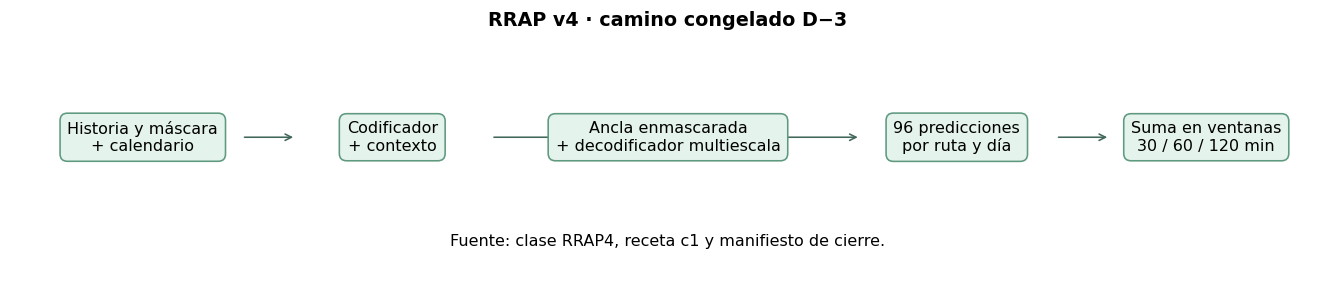

In [3]:
fig, ax = plt.subplots(figsize=(11.5, 2.4), layout="constrained")
ax.set_axis_off()
pasos = ["Historia y máscara\n+ calendario", "Codificador\n+ contexto", "Ancla enmascarada\n+ decodificador multiescala",
         "96 predicciones\npor ruta y día", "Suma en ventanas\n30 / 60 / 120 min"]
pos = [.10, .29, .50, .72, .91]
for x, texto in zip(pos, pasos):
    ax.text(x, .58, texto, ha="center", va="center", transform=ax.transAxes,
            bbox=dict(boxstyle="round,pad=.46", facecolor="#e4f3eb", edgecolor="#5e9980"))
for a, b in zip(pos, pos[1:]):
    ax.annotate("", (b-.073, .58), (a+.075, .58), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="->", color="#42685b"),
                zorder=0)
ax.set_title("RRAP v4 · camino congelado D−3")
ax.text(.5, .13, "Fuente: clase RRAP4, receta c1 y manifiesto de cierre.", ha="center", transform=ax.transAxes)
plt.show()

## **7. Modelo LightGBM L3**

### **7.1. Modelo por ventana y variables**

El boosting ajusta árboles sucesivos en la escala del enlace. En Poisson, una interpretación de la predicción es $widehat y=exp(F(x))$, con $F(x)$ construido por el conjunto aditivo de árboles. En SOBUSA cada fila describe directamente una ventana. La matriz incorpora ruta, calendario, horizonte, perfiles, historia, oferta y señales agregadas permitidas. La receta fe31 fija el orden de columnas y los códigos categóricos para ajuste e inferencia.

### **7.2. Configuración y selección de árboles**

| Ajuste | Configuración congelada |
|---|---|
| Objetivo y criterio de parada | Poisson |
| Número máximo de hojas | 127 |
| Tasa de aprendizaje | 0,03 |
| Observaciones mínimas por hoja | 40 |
| Regularización L2 | 1,0 |
| Bins y muestreo | 255 bins. Fracciones de variables y filas de 1,0. |
| Presupuesto y exportación | 2.000 iteraciones por semilla. Se elige el mínimo de la curva Poisson de parada y se exporta ese prefijo. |

La configuración L3 ya estaba decantada por la etapa de desarrollo. En el cierre se escogió el número de árboles por semilla, sin una nueva búsqueda de configuraciones. No se presenta un ranking de variables L3 como resultado validado. Las explicaciones del GBM empresarial corresponden a otro estimador. [Ke et al., LightGBM](https://papers.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)

## **8. Ensamble SOBUSA v1.0**

La mezcla fusiona las predicciones por clave compatible:

$$
widehat y^{,mathrm{v1}}_{r,t,H}
;=;0.5left(
rac1{5}sum_{s=0}^{4}widehat y^{,mathrm{RRAP},s}_{r,t,H}
ight)
+0.5left(
rac1{5}sum_{s=0}^{4}widehat y^{,mathrm{L3},s}_{r,t,H}
ight).
$$

| Semilla | Época RRAP | Árboles L3 |
|---:|---:|---:|
| 0 | 19 | 383 |
| 1 | 22 | 399 |
| 2 | 26 | 415 |
| 3 | 25 | 419 |
| 4 | 19 | 410 |

*Fuente de la tabla: manifiesto `sobusa-v1.0-p25-d3-r01`.* Se congelaron cinco estados PyTorch, cinco boosters de texto, horario y metadatos. El cargador compara SHA-256 antes de interpretar pesos, carga estados RRAP en CPU con `weights_only=True` y verifica el número de árboles de cada booster. El mero promedio de errores de las semillas no produce el error del promedio de predicciones.

### **7.3. Aprendizaje por ventanas y criterio de selección**

Sea $x_i$ el vector ordenado de variables de la ventana e $F_s^{(m)}(x_i)$ el margen de la semilla $s$ después de $m$ árboles. El modelo aditivo actualiza $F_s^{(m)}=F_s^{(m-1)}+\eta f_{s,m}(x_i)$ y devuelve $\widehat y_{i,s}=\exp(F_s^{(m)}(x_i))$. Es una representación del boosting con enlace log. La API nativa de LightGBM realiza la construcción de árboles, el cálculo de incrementos y el enlace.

Para un conteo $y_i$, la verosimilitud Poisson negativa, omitiendo constantes de la etiqueta, es

$$
\ell_i=\exp(F_s(x_i))-y_i F_s(x_i)
      =\widehat y_{i,s}-y_i\log \widehat y_{i,s}.
$$

El entrenamiento L3 añade restricciones de hojas, soporte mínimo y regularización L2. La configuración del cierre explora el prefijo de una secuencia de 2.000 árboles en el bloque de parada, y toma $m_s^\star=1+\arg\min_{m=0,\ldots,1999}\ell^{\mathrm{parada}}_{s,m}$. El índice $m$ de esa fórmula es la posición desde cero en el registro. El archivo de cada semilla contiene solo el prefijo elegido. La evaluación p25 y la inferencia cargan ese prefijo, sin actualizar la secuencia.

**Fuente de la receta.** `insumos/rrap/src/lgbm_fe31.py` (`FIJOS`, `CONFIGS["L3"]`) y `cierre_v1/entrenar.py` para ajuste, parada y exportación del cierre. El registro de cada booster conserva la curva de pérdida de parada.

### **8.1. Justificación científica de la combinación**

RRAP y LightGBM comparten el objetivo y el calendario, pero construyen la predicción con señales distintas. RRAP corrige un ancla histórica y pronostica una secuencia intradía que acumula por horizonte. L3 usa árboles sobre características de cada ventana y puede aprender interacciones distintas para la misma hora, ruta y horizonte. La heterogeneidad ofrece la posibilidad de que los errores queden en lados opuestos del valor observado. También pueden compartir sesgos por problemas de cobertura, cambios de servicio o rezagos poco informativos.

### **8.2. Covarianza, sesgo y estabilidad entre semillas**

Sean $e_R$ y $e_L$ los errores con signo de las medias de familia en la misma ventana. El error de la mezcla es $e_F=(e_R+e_L)/2$, de modo que su sesgo es el promedio de los sesgos y

$$
\operatorname{Var}(e_F) =
\tfrac{1}{4}\big[\sigma_R^2+\sigma_L^2+
2\rho\sigma_R\sigma_L\big].
$$

Con dispersión comparable, una correlación menor deja más espacio para reducir varianza. El promedio no elimina un sesgo común y una reducción de varianza no prueba una mejora de MASE. Para la pérdida absoluta también se cumple $|e_F|\le (|e_R|+|e_L|)/2$. El límite es el **promedio** de las pérdidas de ambos, de modo que la mezcla todavía puede perder frente a la mejor familia en una ventana o segmento.

Se promedian cinco semillas para atenuar la sensibilidad a la inicialización, al orden de los lotes y a otras diferencias reproducibles del ajuste. Las semillas comparten los datos y pueden tener errores muy correlacionados. Su dispersión describe la estabilidad de las corridas y no equivale a la incertidumbre sobre fechas futuras. Las medias por familia también hacen que cada arquitectura tenga el mismo peso total.

### **8.3. Por qué se conservó el 50/50**

El 50/50 es una **decisión de diseño**, transparente y con pocos grados de libertad. Evita ajustar sobre p25 un parámetro extra y mantiene el reparto por familia al cambiar la escala de la ventana. Los análisis de pesos aprendidos pertenecen al desarrollo; el cierre conserva la regla fijada y la evalúa contra cada familia. La relación sesgo–varianza y la diversidad motivan examinar la mezcla. La evidencia de que funcionó en el agregado proviene de p25; la comparación no establece que 0,5 sea un peso óptimo ni que la misma ponderación generalice a todas las rutas o fechas.

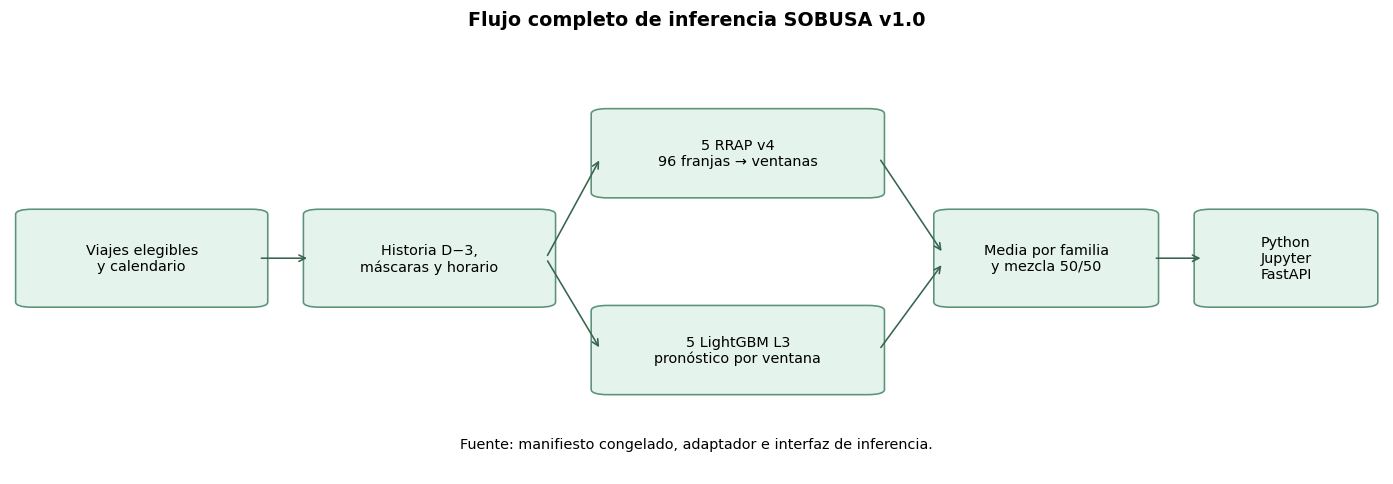

In [4]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 4.1), layout="constrained")
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis("off")

def caja(x, y, w, h, texto):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=.012",
                                facecolor="#e4f3eb", edgecolor="#5b927a"))
    ax.text(x+w/2, y+h/2, texto, ha="center", va="center", fontsize=9)

def flecha(x, y, xx, yy):
    ax.annotate("", (xx, yy), (x, y), arrowprops={"arrowstyle": "->", "color": "#386450"})

caja(.015, .39, .16, .20, "Viajes elegibles\ny calendario")
caja(.225, .39, .16, .20, "Historia D−3,\nmáscaras y horario")
caja(.435, .64, .19, .18, "5 RRAP v4\n96 franjas → ventanas")
caja(.435, .19, .19, .18, "5 LightGBM L3\npronóstico por ventana")
caja(.685, .39, .14, .20, "Media por familia\ny mezcla 50/50")
caja(.875, .39, .11, .20, "Python\nJupyter\nFastAPI")
for puntos in ((.18, .49, .218, .49), (.39, .49, .43, .72), (.39, .49, .43, .28),
               (.633, .72, .68, .5), (.633, .28, .68, .48), (.833, .49, .87, .49)):
    flecha(*puntos)
ax.set_title("Flujo completo de inferencia SOBUSA v1.0")
ax.text(.5, .055, "Fuente: manifiesto congelado, adaptador e interfaz de inferencia.",
        ha="center", fontsize=9)
plt.show()

El diagrama comunica dos consecuencias del diseño. RRAP aporta una curva agregable, mientras L3 aporta una estimación directa por ventana. El ensamble se forma después de alinear ambas familias y se expone mediante una sola interfaz.

### **8.4. Agregación y segundo momento de los errores**

Se promedian las cinco salidas de una familia por cada clave $i=(r,t,H)$,

$$
\bar p_{R,i}=\tfrac{1}{5}\sum_{s=0}^{4}p^{(s)}_{R,i},\qquad
\bar p_{L,i}=\tfrac{1}{5}\sum_{s=0}^{4}p^{(s)}_{L,i},\qquad
\widehat y_{F,i}=\tfrac12\bar p_{R,i}+\tfrac12\bar p_{L,i}.
$$

Si $e_R=\bar p_R-y$ y $e_L=\bar p_L-y$ en el mismo soporte, el término cruzado es $\operatorname{Cov}(e_R,e_L)=\rho\sigma_R\sigma_L$. El segundo momento de la mezcla es

$$
\operatorname{E}[e_F^2]
=\tfrac14\left(\operatorname{Var}(e_R)+\operatorname{Var}(e_L)
  +2\operatorname{Cov}(e_R,e_L)\right)+\left(\tfrac{\operatorname{E}[e_R]+\operatorname{E}[e_L]}{2}\right)^2 .
$$

La covarianza conecta la dispersión de ambas familias y el sesgo común permanece en el término cuadrático. La descomposición explica el error cuadrático esperado, mientras que MASE debe calcularse por separado con la escala y las claves de evaluación. Se muestra Pearson sobre residuos con signo para estudiar esa asociación. La comparación con el error absoluto escalado y los signos opuestos responde a preguntas descriptivas distintas.

## **9. Métricas de evaluación**

### **9.1. Escala estacional y denominadores**

Sea $I$ el conjunto de ventanas con etiqueta y predicción verificables. Para el MASE, $a_{rh}$ es la media de diferencias absolutas de pasajeros entre pares originales y desplazados siete días con igual ruta, horizonte y hora. Los pares provienen de la partición histórica de entrenamiento del archivo de referencia, que abarca el soporte designado de entrenamiento y parada previo a p25. Se conservan sus escalas positivas auditadas. Es una escala de evaluación distinta de la normalización interna de RRAP.

$$
egin{aligned}
operatorname{MASE}&=
rac{1}{|I|}sum_{iin I}
rac{|e_i|}{a_{r_i h_i}},&
operatorname{MAE}&=
rac{1}{|I|}sum_{iin I}|e_i|,\
operatorname{RMSE}&=sqrt{
rac{1}{|I|}sum_{iin I}e_i^2},&
operatorname{WAPE}&=
rac{sum_{iin I}|e_i|}{sum_{iin I}|y_i|},\
operatorname{sMAPE}&=
rac{1}{|I|}sum_{iin I}
rac{2|e_i|}{|y_i|+|widehat y_i|},&
e_i&=widehat y_i-y_i .
end{aligned}
$$

### **9.2. Interpretación de las métricas**

El MASE es adimensional y trata cada ventana evaluable por igual. El MAE y el RMSE se expresan en pasajeros por ventana. El RMSE penaliza más los errores grandes. WAPE y sMAPE se expresan como porcentajes al multiplicar por 100. WAPE requiere volumen observado positivo y da mayor peso a grupos de volumen alto. En sMAPE dos ceros aportan cero y un solo cero aporta 200 %. El sesgo firmado resume sobrepredicción y subpredicción y puede ocultar compensaciones. [Hyndman y Koehler (2006)](https://doi.org/10.1016/j.ijforecast.2006.03.001)

### **9.3. Cálculo reproducible de las escalas y los errores**

Para cada grupo $(r,H)$, sea $\mathcal P_{r,H}$ el conjunto de pares de claves observadas de la partición histórica de entrenamiento que conserva el archivo de referencia. Un par coincide en ruta, hora de origen y horizonte y está separado exactamente siete días. En el cierre esta partición comprende el soporte histórico designado, anterior a la evaluación.

$$
a_{r,H}=\frac{1}{|\mathcal P_{r,H}|}\sum_{(i,i')\in\mathcal P_{r,H}}|y_i-y_{i'}|,
\qquad
\operatorname{MASE}=\frac{\sum_{i\in I}|e_i|/a_{r_i,H_i}}{|I|}.
$$

Primero se exige que $a_{r,H}$ sea positiva y finita. Después se calcula el error en cada clave de evaluación y se aplica la escala del grupo antes de promediar. En contraste, WAPE divide la suma de errores absolutos por la suma de conteos observados. sMAPE normaliza cada par predicción–observación, con contribución cero cuando ambos valen cero. El cuaderno conserva MAE y RMSE en pasajeros por ventana. Los dos cocientes porcentuales se multiplican por 100 al presentarlos. La fuente ejecutable de estas convenciones es `evaluacion.py::escalar` y `evaluacion.py::evaluar`.

## **10. Resultados experimentales**

La tabla pública usa los tres valores globales autorizados, redondeados a seis decimales y cotejados con `cierre_v1/metricas_v1.csv`. La gráfica los representa en la misma escala. Las tablas detalladas y los perfiles de errores se ejecutan con la evidencia privada.

,MASE
RRAP v4,0.587081
LightGBM L3,0.593973
SOBUSA 50/50,0.580325


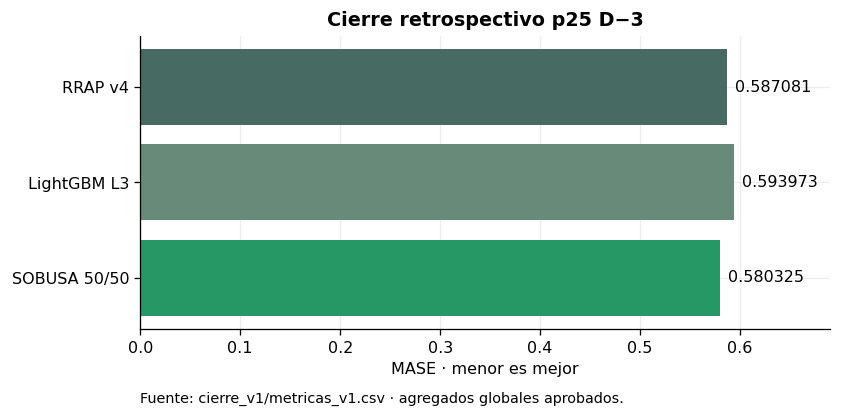

In [5]:
modelos = {"rrap": "RRAP v4", "lgbm": "LightGBM L3", "fijo": "SOBUSA 50/50"}
resultado_publico = pd.Series([.587081, .593973, .580325], index=list(modelos), name="MASE")
if evidencia:
    cierre_metricas = pd.read_csv(CIERRE / "metricas_v1.csv")
    global_cierre = cierre_metricas.loc[cierre_metricas.nivel.eq("global")].set_index("modelo")
    np.testing.assert_allclose(global_cierre.loc[list(modelos), "mase"], resultado_publico, rtol=0, atol=5e-7)
resumen = resultado_publico.rename(index=modelos).to_frame()
display(resumen.style.format("{:.6f}"))

fig, ax = plt.subplots(figsize=(7.2, 3.5), layout="constrained")
barras = ax.barh(resumen.index, resumen.MASE, color=PALETA)
ax.invert_yaxis()
ax.bar_label(barras, fmt="%.6f", padding=5)
ax.set(xlim=(0, .69), xlabel="MASE · menor es mejor", title="Cierre retrospectivo p25 D−3")
ax.text(0, -.25, "Fuente: cierre_v1/metricas_v1.csv · agregados globales aprobados.",
        transform=ax.transAxes, fontsize=9)
plt.show()

El 50/50 reduce el MASE en **0,006755** respecto a RRAP, alrededor de **1,15 %**, y en **0,013648** respecto a L3, alrededor de **2,30 %**. Se trata de diferencias descriptivas sobre ventanas coincidentes. El estudio archivó comparaciones pareadas con bloques móviles de siete días y 2.000 réplicas. El contraste con RRAP no permite concluir una ventaja estadística en ese protocolo. La reutilización de p25 limita cualquier lectura confirmatoria general.

In [6]:
def metricas(v, nombre):
    y, q = v.y_pasajeros.to_numpy(), v[nombre].to_numpy()
    error = q-y
    abs_error = abs(error)
    den = abs(y)+abs(q)
    volumen = abs(y).sum()
    return dict(n=len(y), MASE=np.mean(abs_error/v.escala), MAE=abs_error.mean(),
                RMSE=np.sqrt(np.mean(error**2)), WAPE=100*abs_error.sum()/volumen if volumen else np.nan,
                sMAPE=100*np.divide(2*abs_error, den, out=np.zeros_like(error, dtype=float), where=den>0).mean(),
                sesgo=error.mean())

referencia = None
if evidencia:
    referencia = parquet_archivado("predicciones.parquet")
    claves = ["id_ruta", "origen", "horizonte_min"]
    semillas = [f"{m}_s{s}" for m in ("rrap", "lgbm") for s in range(5)]
    miembros = [*semillas, *modelos]
    pred_congeladas = pd.read_parquet(CIERRE / "predicciones_v1.parquet", columns=[*claves, *miembros])
    d = referencia.drop(columns=miembros).merge(pred_congeladas, how="left", on=claves, validate="one_to_one")
    assert len(d) == len(referencia) and d.escala.gt(0).all()
    for m in miembros:
        tolerancia = 1e-8 if m.startswith("lgbm") else 1e-4
        np.testing.assert_allclose(d[m], referencia[m], rtol=1e-6, atol=tolerancia, equal_nan=False)
    np.testing.assert_allclose(d.fijo, (d.rrap+d.lgbm)/2, rtol=1e-6, atol=1e-4)
    tabla = pd.DataFrame({m: metricas(d, m) for m in miembros}).T
    np.testing.assert_allclose(tabla.loc[list(modelos), "MASE"], resultado_publico, atol=5e-7, rtol=0)
    display(tabla.round(6))
    desgloses = []
    for campo in ("id_ruta", "horizonte_min"):
        for llave, filas in d.groupby(campo):
            for m, etiqueta in modelos.items():
                desgloses.append({"Corte": campo, "Grupo": llave, "Modelo": etiqueta, **metricas(filas, m)})
    display(pd.DataFrame(desgloses).round(4))
    print("Fuente: predicciones v1 del cierre alineadas con la referencia cronológica p25 verificada.")
else:
    print("Resultados por semilla, ruta y horizonte reservados a la evidencia privada.")

Resultados por semilla, ruta y horizonte reservados a la evidencia privada.


In [7]:
if referencia is not None:
    d = d.assign(error=d.fijo-d.y_pasajeros,
                 error_escalado=(d.fijo-d.y_pasajeros).abs()/d.escala, hora=d.origen.dt.hour)
    caso = d.loc[d.dia.eq(FECHA_DEMO) & d.id_ruta.eq(2) & d.horizonte_min.eq(60)].sort_values("origen")
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), layout="constrained")
    d.groupby("hora").error_escalado.mean().plot(ax=ax[0], color=PALETA[2])
    ax[0].set(title="Error por hora", xlabel="Hora de origen (Bogotá)", ylabel="MASE por ventana")
    ax[1].hist(d.error, bins=60, color=PALETA[2])
    ax[1].set(title="Distribución de residuos", xlabel="Pronóstico − observado (pasajeros)", ylabel="Ventanas")
    for col, color in (("y_pasajeros", PALETA[0]), ("fijo", PALETA[2])):
        ax[2].plot(caso.origen.dt.hour + caso.origen.dt.minute/60, caso[col], label=col, color=color)
    ax[2].legend(frameon=False)
    ax[2].set(title="Fecha fija · ruta 2 · 60 min", xlabel="Hora local", ylabel="Pasajeros por ventana")
    fig.suptitle("Fuente: evaluación privada p25 · pronósticos congelados")
    plt.show()
    display(d.groupby(["id_ruta", "horizonte_min"]).error_escalado.agg(
        ventanas="size", mediana="median", p95=lambda s: s.quantile(.95)).round(3))
else:
    print("Residuos y comparación con observados reservados a la evidencia privada.")

Residuos y comparación con observados reservados a la evidencia privada.


El desglose local separa errores por ruta, ventana y hora. La mediana y el percentil 95 de error escalado describen los casos difíciles sin seleccionar una fecha favorable. El ejemplo de trazado usa la fecha ya fijada para la demostración histórica de la API. Las ventanas de una misma jornada se solapan. Por eso la visualización de muchos puntos no equivale a muchas observaciones independientes.

### **10.1. Desglose por ruta, horizonte y función de error**

Las barras se calculan sobre las mismas ventanas evaluables para los tres modelos. La comparación por ruta reúne todos los horizontes y la comparación por horizonte reúne todas las rutas. Cada panel mantiene su denominador MASE original. MAE y RMSE describen magnitud en pasajeros. WAPE y sMAPE se leen en porcentaje con denominadores distintos. Una reducción de MASE no exige una reducción de RMSE si se agravan algunos errores extremos.

In [8]:
if referencia is not None:
    def citar(fig, titulo, fuente="cierre v1, predicciones congeladas y referencia p25 D−3 emparejada"):
        fig.suptitle(titulo, fontweight="bold")
        fig.supxlabel("Fuente: " + fuente + ".", fontsize=9)

    por_grupo = pd.DataFrame(desgloses)
    fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.9), layout="constrained")
    for ax, campo, titulo, unidad in zip(axs, ("id_ruta", "horizonte_min"),
            ("Por ruta", "Por horizonte"), ("Ruta", "Longitud de ventana (minutos)")):
        datos = por_grupo.loc[por_grupo.Corte.eq(campo)].pivot(index="Grupo", columns="Modelo", values="MASE")
        datos[list(modelos.values())].plot.bar(ax=ax, color=PALETA, rot=0, width=.76)
        ax.set(title=titulo, xlabel=unidad, ylabel="MASE · adimensional")
        ax.legend(frameon=False, fontsize=8)
    citar(fig, "Error escalado de cada familia y del ensamble")
    plt.show()

    fig, axs = plt.subplots(2, 2, figsize=(10.5, 6.3), layout="constrained")
    for ax, metrica, unidad in zip(axs.flat, ("MAE", "RMSE", "WAPE", "sMAPE"),
                                   ("pasajeros por ventana", "pasajeros por ventana", "%", "%")):
        valores = tabla.loc[list(modelos), metrica].rename(index=modelos)
        barras = ax.barh(valores.index, valores, color=PALETA)
        ax.bar_label(barras, fmt="%.2f", padding=4, fontsize=9)
        ax.margins(x=.19)
        ax.invert_yaxis()
        ax.set(title=metrica, xlabel=unidad, ylabel="Modelo")
    citar(fig, "Métricas complementarias sobre el mismo conjunto evaluable")
    plt.show()
else:
    print("Comparaciones por ruta, horizonte y métricas complementarias: disponibles con la evidencia privada.")

Comparaciones por ruta, horizonte y métricas complementarias: disponibles con la evidencia privada.


### **10.2. Estabilidad de las semillas**

Los puntos representan ajustes individuales. La línea indica el error del promedio de sus pronósticos, útil para distinguir la estabilidad de ejecución del resultado de combinar. Las cinco corridas comparten los periodos evaluados. La figura no aporta cinco réplicas independientes de la generalización.

In [9]:
if referencia is not None:
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained", sharey=True)
    for ax, familia, color in zip(axs, ("rrap", "lgbm"), PALETA[:2]):
        series = tabla.loc[[f"{familia}_s{s}" for s in range(5)], "MASE"]
        ax.scatter(range(5), series, color=color, s=54, label="Modelo individual")
        ax.axhline(tabla.loc[familia, "MASE"], color=PALETA[2], linestyle="--",
                   label="Evaluación de la media de predicciones")
        ax.set(title=modelos[familia], xlabel="Semilla", ylabel="MASE · adimensional", xticks=range(5))
        ax.legend(frameon=False, fontsize=8)
    citar(fig, "Variabilidad entre las cinco semillas por familia")
    plt.show()

### **10.3. Correlación y complementariedad**

La nube compara residuos con signo, en pasajeros por ventana. Los cuadrantes opuestos corresponden a errores que pueden compensarse. El coeficiente de Pearson resume asociación lineal y puede ser alto incluso cuando algunas ventanas tienen signos opuestos. La tabla contrasta esa medida con la correlación de magnitudes escaladas y con tasas de días favorables. Las líneas diarias son promedios de ventanas de cada día. Un valor negativo favorece al 50/50 en ese día, sin establecer significancia a partir de los puntos trazados.

In [10]:
if referencia is not None:
    errores = d[["rrap", "lgbm", "fijo"]].sub(d.y_pasajeros, axis=0)
    abs_esc = errores.abs().div(d.escala, axis=0)
    opuestos = errores.rrap.mul(errores.lgbm).lt(0)
    comparacion = d[["id_ruta", "horizonte_min", "dia"]].assign(
        rrap=abs_esc.rrap, lgbm=abs_esc.lgbm, fijo=abs_esc.fijo,
        corr_r=errores.rrap, corr_l=errores.lgbm, opuestos=opuestos)
    diario_comp = comparacion.groupby("dia")[["rrap", "lgbm", "fijo"]].mean()
    como = pd.DataFrame([{
        "Pearson residuos con signo": errores.rrap.corr(errores.lgbm),
        "Pearson error absoluto escalado": abs_esc.rrap.corr(abs_esc.lgbm),
        "% ventanas con signos opuestos": 100*opuestos.mean(),
        "Días con menor MASE que L3": (diario_comp.fijo < diario_comp.lgbm).sum(),
        "Días con menor MASE que RRAP": (diario_comp.fijo < diario_comp.rrap).sum(),
        "Días evaluados": len(diario_comp),
    }])
    display(como.round(4))
    print("Complementariedad descriptiva. Fuente: referencia p25 y predicciones del cierre.")

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.1), layout="constrained")
    nube = axs[0].hexbin(errores.rrap, errores.lgbm, gridsize=42, mincnt=1, bins="log", cmap="Greens")
    axs[0].axhline(0, color="#59615f", linewidth=.7)
    axs[0].axvline(0, color="#59615f", linewidth=.7)
    axs[0].set(title="Complementariedad en la misma ventana", xlabel="Residuo RRAP (pasajeros)",
               ylabel="Residuo LightGBM (pasajeros)")
    fig.colorbar(nube, ax=axs[0], label="Ventanas por celda · escala log")
    for (familia, color) in zip(("rrap", "lgbm"), PALETA[:2]):
        diferencia = diario_comp.fijo-diario_comp[familia]
        axs[1].plot(diferencia.index, diferencia, color=color, label=f"50/50 − {modelos[familia]}", alpha=.9)
    axs[1].axhline(0, color="#59615f", linewidth=1)
    axs[1].set(title="Ventaja o pérdida descriptiva por día", xlabel="Fecha p25",
               ylabel="Diferencia de MASE diario")
    axs[1].legend(frameon=False, fontsize=8)
    citar(fig, "Errores emparejados de RRAP v4 y LightGBM L3")
    plt.show()
else:
    print("La correlación, los signos opuestos y la comparación diaria requieren datos privados.")

La correlación, los signos opuestos y la comparación diaria requieren datos privados.


### **10.4. Mejoras y deterioros por ruta y horizonte**

Cada celda compara el MASE del 50/50 con el de la familia indicada en el mismo segmento. En los mapas de cambio, el denominador es el MASE de la familia y los dos mapas usan la misma escala. Un valor negativo indica mejora del ensamble y uno positivo indica deterioro. La segmentación ayuda a identificar casos de fallo sin convertir el mejor resultado de cada celda en una política de selección a posteriori.

In [11]:
if referencia is not None:
    grupos = comparacion.groupby(["id_ruta", "horizonte_min"])[["rrap", "lgbm", "fijo"]].mean()
    nivel = grupos.fijo.unstack()
    relativos = {m: (100*(grupos.fijo-grupos[m])/grupos[m]).unstack() for m in ("rrap", "lgbm")}
    maximo = max(float(z.abs().max().max()) for z in relativos.values())
    fig, axs = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
    for ax, panel, titulo, unidad in zip(axs, [nivel, *relativos.values()],
        ["Error del 50/50", "Cambio frente a RRAP", "Cambio frente a L3"], ["MASE", "%", "%"]):
        limites = {} if unidad == "MASE" else dict(vmin=-maximo or -1, vmax=maximo or 1)
        mapa = ax.imshow(panel, cmap="Greens" if unidad=="MASE" else "RdBu_r", **limites)
        for i in range(panel.shape[0]):
            for j in range(panel.shape[1]):
                v = panel.iloc[i, j]
                ax.text(j, i, f"{v:.3f}" if unidad=="MASE" else f"{v:+.1f}%",
                        ha="center", va="center", fontsize=9,
                        color="white" if mapa.norm(v) > .77 or (unidad=="%" and mapa.norm(v)<.19) else "#16332a")
        ax.set(title=titulo, xlabel="Horizonte (minutos)", ylabel="Ruta")
        ax.set_xticks(range(len(panel.columns)), panel.columns)
        ax.set_yticks(range(len(panel.index)), panel.index)
        ax.grid(False)
        fig.colorbar(mapa, ax=ax, shrink=.72, label=unidad)
    citar(fig, "Error y cambio relativo del ensamble por ruta y horizonte")
    plt.show()

### **10.5. Cotejo de métricas y variación mensual**

Se comprueban MAE, RMSE, WAPE, sMAPE, MASE, sesgo y tamaño del soporte contra el cierre para las trece salidas. Los porcentajes se devuelven a la convención del CSV antes de comparar. El perfil mensual añade el número de ventanas que aporta cada mes. Las diferencias temporales pueden reflejar cambios en la demanda y en la cobertura. Los tres meses pertenecen al mismo cierre retrospectivo.

In [12]:
if referencia is not None:
    columnas_cierre = {"MASE": "mase", "MAE": "mae", "RMSE": "rmse",
                       "WAPE": "wape", "sMAPE": "smape", "sesgo": "sesgo", "n": "n"}
    control_cierre = tabla[list(columnas_cierre)].rename(columns=columnas_cierre).copy()
    control_cierre[["wape", "smape"]] /= 100
    comparadores = global_cierre.loc[control_cierre.index, control_cierre.columns]
    np.testing.assert_allclose(control_cierre, comparadores, rtol=1e-9, atol=1e-10)
    print(f"Métricas globales reproducidas para {len(control_cierre)} salidas "
          f"sobre {len(d):,} ventanas evaluables. Fuente: metricas_v1.csv.")

    periodo = d.dia.dt.to_period("M")
    mensual = abs_esc.groupby(periodo).mean()
    soporte = periodo.value_counts().reindex(mensual.index)
    fig, ax = plt.subplots(figsize=(9.5, 4), layout="constrained")
    mensual.rename(columns=modelos).plot.bar(ax=ax, rot=0, color=PALETA, width=.72)
    ax.set(title="MASE mensual en el cierre p25 D−3",
           xlabel="Mes local", ylabel="MASE · adimensional")
    ax.set_xticks(range(len(mensual.index)),
                  [f"{mes}\n(n = {soporte[mes]:,})" for mes in mensual.index])
    ax.legend(frameon=False)
    fig.supxlabel("Fuente: pronósticos congelados y referencia p25 emparejada.", fontsize=9)
    plt.show()
else:
    print("El cotejo de todas las métricas y el perfil mensual requieren la evidencia privada.")

El cotejo de todas las métricas y el perfil mensual requieren la evidencia privada.


## **11. Inferencia reproducible**

### **11.1. Dependencias, integridad y motor común**

El código llama a `sobusa_v1_runtime.interfaz.predecir`, el mismo punto de entrada que usan FastAPI y la CLI. Configure `SOBUSA_RUNTIME_DIR` con la raíz de la distribución privada si el notebook se abre fuera de ella. `SOBUSA_ARTEFACTOS_DIR` indica el directorio de los diez modelos, el horario y el manifiesto. Use `SOBUSA_MODO_NOTEBOOK=retrospectivo` con `SOBUSA_HISTORICO_DIR` para repetir el 1 de mayo de 2025. Con los pesos y el runtime disponibles, el modo predeterminado genera viajes ficticios antes del corte y usa los pesos reales. Cuando esos activos faltan, la celda informa la dependencia.

In [13]:
requeridas = ["pandas", "numpy", "matplotlib", "torch", "lightgbm", "pyarrow", "sklearn"]
faltan = [m for m in requeridas if importlib.util.find_spec(m) is None]
ubicacion = os.getenv("SOBUSA_RUNTIME_DIR")
raiz = Path(ubicacion) if ubicacion else next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p/"sobusa_v1_runtime").is_dir()), Path.cwd())
archivo_artefactos = Path(os.getenv("SOBUSA_ARTEFACTOS_DIR", f"artefactos/{VERSION}"))
if not archivo_artefactos.is_absolute():
    archivo_artefactos = raiz / archivo_artefactos
modelos_esperados = [f"rrap_s{i}.pt" for i in range(5)] + [f"lgbm_s{i}.txt" for i in range(5)]
presentes = all((archivo_artefactos / f).is_file()
                for f in [*modelos_esperados, "manifiesto.json", "horario.csv"])
runtime = (raiz/"sobusa_v1_runtime/interfaz.py").is_file()
if faltan:
    print("Dependencias de inferencia ausentes:", ", ".join(faltan))
prediccion = None
if runtime and presentes and not faltan:
    manifiesto_path = archivo_artefactos / "manifiesto.json"
    if huella(manifiesto_path) != SHA_MANIFIESTO:
        raise ValueError("El manifiesto no coincide con la versión aprobada.")
    inventario_modelo = json.loads(manifiesto_path.read_text(encoding="utf-8"))
    assert sorted(a["archivo"] for a in inventario_modelo["artefactos"]) == sorted(modelos_esperados)
    for a in inventario_modelo["artefactos"]:
        if huella(archivo_artefactos / a["archivo"]) != a["sha256"]:
            raise ValueError("Artefacto alterado: " + a["archivo"])
    sys.path.insert(0, str(raiz))
    from sobusa_v1_runtime.interfaz import predecir

    modo = os.getenv("SOBUSA_MODO_NOTEBOOK", "sintetico")
    if modo == "retrospectivo" and not os.getenv("SOBUSA_HISTORICO_DIR"):
        print("Configure SOBUSA_HISTORICO_DIR para reproducir el histórico del ejemplo.")
    else:
        prediccion = predecir(FECHA_DEMO, RUTAS, HORIZONTES, modo=modo)
        meta = prediccion["metadata"]
        assert meta["version"] == VERSION and meta["modo"] == modo
        f = pd.DataFrame(prediccion["filas"])
        assert set(zip(f.idruta, f.horizonte_min)) == {(r,h) for r in RUTAS for h in HORIZONTES}
        np.testing.assert_allclose(f.demanda_pred, (f.demanda_rrap_v4+f.demanda_lightgbm_l3)/2,
                                   rtol=1e-6, atol=1e-4)
        if modo == "retrospectivo":
            assert len(meta["paridad"]) == 13 and not any(x["fuera_tolerancia"] for x in meta["paridad"].values())
        print(f"Inferencia {modo}: {len(f)} filas, diez artefactos verificados.")
else:
    print("Para generar predicciones, instale el worker y suministre el runtime y los diez pesos congelados.")

Para generar predicciones, instale el worker y suministre el runtime y los diez pesos congelados.


In [14]:
if prediccion is not None:
    campos = {"demanda_rrap_v4": "RRAP v4", "demanda_lightgbm_l3": "LightGBM L3", "demanda_pred": "SOBUSA 50/50"}
    vista = f.loc[f.idruta.eq(2) & f.horizonte_min.eq(60)].copy()
    x = pd.to_datetime(vista.franja_inicio)
    fig, ax = plt.subplots(figsize=(9, 3.7), layout="constrained")
    for (col, etiqueta), color in zip(campos.items(), PALETA):
        ax.plot(x.dt.hour+x.dt.minute/60, vista[col], label=etiqueta, color=color)
    ax.set(title=f"Inferencia {meta['modo']} · ruta 2 · 60 min",
           xlabel="Hora de salida programada (Bogotá)", ylabel="Pasajeros por ventana")
    ax.legend(frameon=False)
    plt.show()
else:
    print("El gráfico de inferencia requiere un resultado válido del motor común.")

El gráfico de inferencia requiere un resultado válido del motor común.


### **11.2. Consumo desde Python y FastAPI**

**Ejemplo Python.** El paso anterior puede invocarse como `predecir("2025-05-01", [2,16,21], [30,60,120], modo="sintetico")`, o mediante `python -m sobusa_v1_runtime --fecha 2025-05-01 --modo sintetico` desde la raíz del runtime. El ejemplo FastAPI usa el mismo modelo explícito y consulta puntos a 60 minutos. Solo se activa si se configura un servicio local y un token efímero de operador, según la [guía de inferencia](../../README_INFERENCIA.md).

In [15]:
from urllib.parse import urlsplit
from urllib.request import Request, urlopen

url_api = os.getenv("SOBUSA_NOTEBOOK_API_URL")
token_api = os.getenv("SOBUSA_OPERADOR_TOKEN")
solicitud = dict(modelo="sobusa_v1", version=VERSION, fecha=FECHA_DEMO, rutas=RUTAS, horizontes=HORIZONTES)
if url_api and token_api:
    url = urlsplit(url_api)
    if url.scheme != "http" or url.hostname != "127.0.0.1" or url.username or url.password:
        raise ValueError("El ejemplo API solo acepta un servicio HTTP local en 127.0.0.1.")
    base = url_api.rstrip("/") + "/api/v1"
    cabeceras = {"Authorization": "Bearer " + token_api, "Content-Type": "application/json"}
    with urlopen(Request(base+"/candidate-runs", data=json.dumps(solicitud).encode(), headers=cabeceras), timeout=90) as r:
        corrida = json.load(r)
    with urlopen(Request(base+f"/candidate-runs/{corrida['run_id']}/predictions?horizonte_min=60&tamano=500",
                         headers=cabeceras), timeout=15) as r:
        pagina = json.load(r)
    assert corrida["metadata"]["version"] == VERSION
    assert all(row["horizonte_min"]==60 for row in pagina["datos"])
    if prediccion is not None:
        assert corrida["metadata"]["snapshot"] == meta["snapshot"]
        columnas = ["idruta", "franja_inicio", *campos]
        api = pd.DataFrame(pagina["datos"])[columnas].sort_values(columnas[:2]).reset_index(drop=True)
        py = f.loc[f.horizonte_min.eq(60), columnas].sort_values(columnas[:2]).reset_index(drop=True)
        pd.testing.assert_frame_equal(api, py, check_dtype=False, atol=1e-8, rtol=1e-6)
    print("Consulta y paginación de FastAPI comprobadas para el horizonte de 60 minutos.")
else:
    print("Ejemplo API opcional: configure SOBUSA_NOTEBOOK_API_URL y un token de operador local.")

Ejemplo API opcional: configure SOBUSA_NOTEBOOK_API_URL y un token de operador local.


## **12. Integración con SOBUSA**

### **12.1. API candidata y registro empresarial**

El backend conserva 15 rutas empresariales. `gbm_fe31` usa la implementación de boosting de scikit-learn y el registro empresarial. El candidato requiere `SOBUSA_CANDIDATO_LOCAL=1` y la selección explícita `sobusa_v1` con su versión. El worker separado evita imponer al backend las versiones de bibliotecas del candidato.

### **12.2. Dashboard y simulación de frecuencia**

La API registra corridas candidatas en memoria y devuelve pronósticos por familia, mezcla y metadatos de versión y cobertura. Los endpoints candidatos no persisten pronósticos en las tablas empresariales. La simulación de despacho se apoya en el pronóstico a 60 minutos y necesita los parámetros de simulación correspondientes. El dashboard actual consume los endpoints empresariales. Incorporar una vista candidata en el dashboard y validar persistencia e intervalos requieren trabajo separado.

## **13. Discusión y limitaciones**

### **13.1. Coherencia y generalización**

RRAP produce primero una curva de 96 franjas y suma en ventanas, mientras L3 pronostica directamente por horizonte. Esa diferencia da margen a errores complementarios y también a incoherencia aditiva. La suma de subventanas se examinó en el diagnóstico retrospectivo y el cierre conservó las salidas por horizonte. La aditividad importa al traducir conteos en recursos discretos. Se recomienda usar el horizonte de la decisión al interpretar la simulación.

La reducción agregada de error no garantiza mejoras por ruta, horizonte o día. Los perfiles privados permiten verificar dónde se concentra el error. El tamaño de la muestra depende de la cobertura de etiquetas y del tipo de día, y las franjas superpuestas exigen inferencia temporal por bloques. Las escalas y el horario se congelaron sin usar las etiquetas de evaluación. Los posibles cambios retrospectivos del snapshot y la selección previa de configuraciones limitan la generalización.

### **13.2. Operación y trabajo futuro**

El modelo candidato carece de intervalos calibrados. La cobertura madura insuficiente de varios estratos impidió aprobar la calibración con los datos disponibles. Falta validar fechas nuevas con entradas versionadas y recibidas antes del corte, además de validar con PostgreSQL los flujos de persistencia que lo requieran.

## **14. Conclusiones**

La mezcla congelada obtuvo el menor MASE global entre los tres comparadores de p25 D−3. La verificación cubrió los diez modelos por semilla, las medias por familia y el 50/50. Un único motor sirve Python, Jupyter y FastAPI y separa el pronóstico de pasajeros de la simulación puntual de frecuencias. Esta evidencia respalda la reproducción retrospectiva y una demostración sintética con activos autorizados. La puesta en operación depende de la disponibilidad real al corte, la validación prospectiva y la decisión sobre intervalos y persistencia.

## **15. Reproducibilidad y referencias**

**Entorno verificado.** Python 3.12.14 AMD64 CPU, NumPy 2.3.5, pandas 3.0.1, LightGBM 4.6.0, PyTorch 2.7.1, PyArrow 20.0.0, scikit-learn 1.6.1, Matplotlib 3.10.3 e ipykernel 6.29.5. La instalación usa el lock separado del worker. Las semillas congeladas son 0 a 4 para cada familia. El backend usa su propio lock.

| Ancla | SHA-256 |
|---|---|
| Manifiesto congelado | `d6db1f83e479730c48371535781461016f02543d327576b7fabd9bbf4c383420` |
| Distribución privada de inferencia Windows AMD64 | `bfe299861679be0422bdba4b838942515a69d46aeac134eb3bb13637236f6b3c` |

El repositorio conserva `app/` (API y servicios), `dashboard/`, `dependencias/`, `ejemplos/` y `eda/`. Los activos autorizados se proporcionan localmente según el [README de inferencia](../../README_INFERENCIA.md). Para las celdas detalladas, `SOBUSA_EVIDENCIA_DIR` apunta al directorio privado que contiene `desarrollo_modelo_original`, con `cierre_v1` y `resultados`. La publicación no incorpora las tablas por fila, los pesos, el código privado ni las salidas detalladas. Este cuaderno no lanza entrenamiento ni selección.

```powershell
& ./dependencias/instalar-local.ps1 -Python python -Ruedas <directorio-autorizado>
& ./.venv-worker/Scripts/python.exe -m ipykernel install --user --name sobusa-v1-worker
& ./.venv-worker/Scripts/python.exe -m sobusa_v1_runtime --fecha 2025-05-01 --modo sintetico
```

**Documentos del estudio.** `AUDITORIA.md` e inventario de viajes (procedencia), `PROTOCOLO.md`, `AUDITORIA_V1.md` y preflight (diseño y madurez), `cierre_v1/INFORME_CIERRE.md`, `metricas_v1.csv` y `TOLERANCIAS.md` (resultados y criterios de paridad), guía y verificación de la distribución privada (integración).

### **15.1. De los experimentos originales al notebook reproducible**

Las rutas de desarrollo siguientes son relativas a la copia privada de `desarrollo_modelo_original/`. Los nombres permiten localizar exactamente el código y los registros con los que se cerró la versión. La reproducción de inferencia empieza con artefactos ya entrenados y la reproducción de métricas empieza con pronósticos ya archivados.

| Etapa | Fuente y evidencia |
|---|---|
| Receta RRAP v4 | `insumos/rrap/src/rrap_v4.py`: clase `RRAP4`, preparación de lotes, pérdidas y bucle de ajuste. El cierre usa c1, semillas 0–4, `ancla=True`, `multiescala=True` y el adaptador de lote de `preflight_v1/rrap_entrada.py`. |
| Receta LightGBM L3 | `insumos/rrap/src/lgbm_fe31.py`: constantes `FIJOS` y `CONFIGS["L3"]`. El cierre usa LightGBM nativo, Poisson, semillas 0–4, tasa 0,03 y hasta 2.000 árboles por semilla. |
| Entrenamiento de los diez artefactos | `cierre_v1/entrenar.py`. Leyó los controles previos y el corte p25, ajustó ambas familias y exportó el manifiesto. `cierre_v1/entrenamiento.log` registra las épocas RRAP. `cierre_v1/reanudacion.log` registra la reanudación de la exportación LightGBM. |
| Configuración, pesos y curvas | `cierre_v1/sobusa-v1.0-p25-d3-r01/`: `manifiesto.json`, `horario.csv`, `rrap_s0.pt`, `rrap_s1.pt`, `rrap_s2.pt`, `rrap_s3.pt`, `rrap_s4.pt`, `lgbm_s0.txt`, `lgbm_s1.txt`, `lgbm_s2.txt`, `lgbm_s3.txt`, `lgbm_s4.txt`. Curvas: los cinco `rrap_s*.csv` y cinco `lgbm_s*.csv` junto a los modelos. |
| Evaluación de cierre | `cierre_v1/validar.py` cargó y ejecutó los diez modelos para el periodo, alineó pronósticos con la referencia e invocó `evaluacion.py::evaluar`. Generó `predicciones_v1.parquet`, `metricas_v1.csv` y `diferencias_metricas.csv` bajo `cierre_v1/`. `validacion.json`, `validacion.log` y `TOLERANCIAS.md` consignan aceptación y umbrales. |
| Fuente histórica de comparación | `resultados/cronologico/p25/predicciones.parquet` contiene las claves comunes, etiquetas, escala MASE y pronósticos de referencia. `intervalos.csv`, `correlacion_errores.csv` y `complementariedad.csv` en la misma carpeta documentan análisis del protocolo cronológico. |
| Motor reutilizable | `sobusa_v1_runtime/interfaz.py::predecir` llama al adaptador, carga el manifiesto y valida paridad en modo retrospectivo. `datos.py` comprueba artefactos. `fe.py`, `entrada.py`, `rrap.py`, `comun.py` y `adaptador.py` preparan y alinean las dos familias. `__main__.py` y `app/ml/sobusa_v1_worker.py` consumen la misma interfaz desde CLI y FastAPI. |

### **15.2. Qué ejecuta cada bloque**

| Bloque del notebook | Tipo de ejecución | Archivos y código de origen |
|---|---|---|
| Configuración e inventario del capítulo 3 | Lectura y control de evidencia. EDA recalculado con datos locales autorizados. | `resultados/viajes.csv`, `resultados/cronologico/p25/serie_fuente.parquet`, manifiesto y EDA originales. Perfiles y resúmenes calculados en el notebook sobre franjas válidas. |
| Diagramas de los capítulos 6 y 8 | Ilustraciones técnicas, sin observaciones empresariales. | Arquitectura `RRAP4`, configuración congelada, adaptador e interfaz. |
| Tabla y gráfico globales del capítulo 10 | Muestran el agregado público archivado y, si hay evidencia privada, lo cotejan con el cierre. | `cierre_v1/metricas_v1.csv`. |
| Métricas y diagnósticos detallados del capítulo 10 | Recalculan errores y métricas por clave y generan figuras. | `cierre_v1/predicciones_v1.parquet` y referencia p25 con SHA-256. Fórmulas de `evaluacion.py::evaluar`, con WAPE y sMAPE mostrados en porcentaje. |
| Capítulo 11 · llamada Python | Ejecuta los diez modelos sobre una fecha y comprueba el promedio. | Distribución privada, motor común, manifiesto, horario y snapshot bajo `SOBUSA_HISTORICO_DIR`. En modo sintético se usan entradas ficticias y los mismos pesos reales. |
| Capítulo 11 · llamada FastAPI | Ejemplo opcional que usa una API local y compara las filas de 60 min con Python. | `app/api/candidatos.py`, `app/servicios_candidatos.py` y el worker del candidato. |
| Control de evidencia del capítulo 10 | Coteja nuevamente las métricas de todas las semillas y familias contra el CSV de cierre. | `cierre_v1/metricas_v1.csv` y la tabla recalculada en el capítulo. |

Las celdas del notebook no ajustan pesos. Los archivos de cierre se conservan como referencia de la corrida original. Sus equivalencias se comprueban con tolerancias declaradas, y la llamada retrospectiva devuelve puntos calculados por los modelos, no valores copiados desde el CSV de métricas.

### **15.3. Referencias bibliográficas**


- Hyndman, R. J., y Koehler, A. B. (2006). *Another look at measures of forecast accuracy*. International Journal of Forecasting, 22(4), 679–688. [Artículo](https://doi.org/10.1016/j.ijforecast.2006.03.001)
- Ke, G. et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS 30. [Artículo](https://papers.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)
- Challu, C. et al. (2023). *N-HiTS: Neural Hierarchical Interpolation for Time Series Forecasting*. Antecedente para construir representaciones a distintas escalas. [Artículo](https://arxiv.org/abs/2201.12886)
- Wang, X., Hyndman, R. J., Li, F., y Kang, Y. (2023). *Forecast combinations: An over 50-year review*. International Journal of Forecasting. [Artículo](https://doi.org/10.1016/j.ijforecast.2022.11.005)
- Cawley, G. C., y Talbot, N. L. C. (2010). *On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation*. JMLR, 11, 2079–2107. [Artículo](https://www.jmlr.org/papers/v11/cawley10a.html)

- Smyl, S. (2020). *A hybrid method of exponential smoothing and recurrent neural networks for time series forecasting*. International Journal of Forecasting, 36(1), 75–85. [Artículo](https://doi.org/10.1016/j.ijforecast.2019.03.017)
- Montero-Manso, P., Athanasopoulos, G., Hyndman, R. J., y Talagala, T. S. (2020). *FFORMA: Feature-based forecast model averaging*. International Journal of Forecasting, 36(1), 86–92. [Artículo](https://doi.org/10.1016/j.ijforecast.2019.02.011)
- Athanasopoulos, G., Hyndman, R. J., Kourentzes, N., y Petropoulos, F. (2017). *Forecasting with temporal hierarchies*. European Journal of Operational Research, 262(1), 60–74. [Artículo](https://doi.org/10.1016/j.ejor.2017.02.046)
- Gneiting, T. (2011). *Making and Evaluating Point Forecasts*. Journal of the American Statistical Association, 106(494), 746–762. [Artículo](https://doi.org/10.1198/jasa.2011.r10138)
- Rocco di Torrepadula, F., Napolitano, E. V., Di Martino, S., y Mazzocca, N. (2024). *Machine Learning for public transportation demand prediction: A Systematic Literature Review*. Engineering Applications of Artificial Intelligence, 137, 109166. [Artículo](https://doi.org/10.1016/j.engappai.2024.109166)